# Лекція: Атом водню в квантовій механіці

*Теорія, аналітичний розв'язок рівняння Шредінгера та символьні обчислення в SymPy*

---

## Вступ

Атом водню — найпростіша фізична система, для якої рівняння Шредінгера розв'язується **точно**, аналітично. Він складається з одного протона (ядра) та одного електрона, що взаємодіють кулонівськими силами. Розв'язання цієї задачі:

- дає точні енергетичні рівні, що пояснюють атомні спектри (серії Лаймана, Бальмера, Пашена);
- вводить квантові числа $n, l, m$ та поняття атомних орбіталей;
- слугує базовою моделлю для всієї атомної та молекулярної фізики, квантової хімії та спектроскопії;
- є зручним полігоном для демонстрації можливостей систем символьних обчислень (SymPy).

У цьому ноутбуці ми пройдемо весь шлях: від гамільтоніана атома водню — до явного вигляду хвильових функцій, енергій, середніх значень фізичних величин та візуалізації орбіталей, супроводжуючи кожен теоретичний крок відповідним обчисленням у Python/SymPy.

## 1. Рівняння Шредінгера для атома водню

### 1.1. Стаціонарне рівняння Шредінгера

$$
\hat{H}\,\psi(\mathbf r) = E\,\psi(\mathbf r)
$$

### 1.2. Гамільтоніан (в системі центра мас)

Для електрона в кулонівському полі ядра із зарядом $Ze$:

$$
\hat{H} = -\frac{\hbar^2}{2m_e}\nabla^2 - \frac{Ze^2}{r}
$$

де $m_e$ — маса електрона, $e$ — заряд електрона, $r=|\mathbf r|$ — відстань електрона від ядра. Для атома водню $Z=1$; для воднеподібних йонів (He$^+$, Li$^{2+}$, …) $Z=2,3,\dots$

Далі працюємо в **атомних одиницях** ($\hbar=m_e=e=1$) — саме в них працює модуль `sympy.physics.hydrogen`.

### 1.3. Лапласіан у сферичних координатах

$$
\nabla^2 = \frac{1}{r^2}\frac{\partial}{\partial r}\!\left(r^2\frac{\partial}{\partial r}\right)
+\frac{1}{r^2\sin\theta}\frac{\partial}{\partial\theta}\!\left(\sin\theta\frac{\partial}{\partial\theta}\right)
+\frac{1}{r^2\sin^2\theta}\frac{\partial^2}{\partial\phi^2}
$$

Повне рівняння Шредінгера:

$$
\left[-\frac{\hbar^2}{2m_e}\left(
\frac{1}{r^2}\frac{\partial}{\partial r}\!\Big(r^2\frac{\partial}{\partial r}\Big)
+\frac{1}{r^2\sin\theta}\frac{\partial}{\partial\theta}\!\Big(\sin\theta\frac{\partial}{\partial\theta}\Big)
+\frac{1}{r^2\sin^2\theta}\frac{\partial^2}{\partial\phi^2}\right)
-\frac{Ze^2}{r}\right]\Psi = E\Psi
$$

## 2. Розділення змінних. Оператор моменту імпульсу

Шукаємо розв'язок у формі добутку:

$$
\Psi_{nlm}(r,\theta,\phi) = R_{nl}(r)\,Y_l^m(\theta,\phi)
$$

де $n=1,2,3,\dots$ — головне квантове число, $l=0,1,\dots,n-1$ — орбітальне, $m=-l,\dots,+l$ — магнітне.

Кутова частина лапласіана — це, з точністю до множника, оператор квадрата орбітального моменту імпульсу:

$$
\hat{\mathbf L}^2 = -\hbar^2\left[\frac{1}{\sin\theta}\frac{\partial}{\partial\theta}\!\Big(\sin\theta\frac{\partial}{\partial\theta}\Big)+\frac{1}{\sin^2\theta}\frac{\partial^2}{\partial\phi^2}\right]
$$

Рівняння Шредінгера набуває вигляду:

$$
\left[-\frac{1}{2}\left(\frac{1}{r^2}\frac{\partial}{\partial r}\Big(r^2\frac{\partial}{\partial r}\Big)-\frac{\hat{\mathbf L}^2}{\hbar^2 r^2}\right)-\frac{Ze^2}{r}\right]\Psi=E\Psi
$$

Оскільки $\hat{\mathbf L}^2 Y_l^m = \hbar^2 l(l+1) Y_l^m$, задача зводиться до радіального рівняння з відцентровим доданком $l(l+1)/r^2$ та окремої кутової задачі.

## 3. Кутова частина: сферичні гармоніки

### 3.1. Розділення $\Theta(\theta)$ і $\Phi(\phi)$

Азимутальна частина:

$$
\frac{d^2\Phi}{d\phi^2}+m^2\Phi=0 \;\;\Rightarrow\;\; \Phi(\phi)=\frac{1}{\sqrt{2\pi}}e^{im\phi}, \qquad m\in\mathbb Z
$$

Полярна частина (після $\lambda=\hbar^2 l(l+1)$):

$$
\frac{1}{\sin\theta}\frac{d}{d\theta}\!\Big(\sin\theta\frac{d\Theta}{d\theta}\Big)+\Big[l(l+1)-\frac{m^2}{\sin^2\theta}\Big]\Theta=0
$$

### 3.2. Рівняння Лежандра

Заміна $x=\cos\theta$ дає асоційоване рівняння Лежандра:

$$
\frac{d}{dx}\!\Big[(1-x^2)\frac{dP}{dx}\Big]+\Big[l(l+1)-\frac{m^2}{1-x^2}\Big]P=0,\qquad x\in[-1,1]
$$

Регулярні розв'язки — асоційовані поліноми Лежандра $P_l^m(x)$, при цілих $l\ge0$, $|m|\le l$:

$$
P_l^m(x) = (-1)^m(1-x^2)^{m/2}\frac{d^m}{dx^m}P_l(x)
$$

### 3.3. Нормування та остаточний вигляд

$$
\boxed{\,Y_l^m(\theta,\phi)=(-1)^m\sqrt{\frac{2l+1}{4\pi}\frac{(l-m)!}{(l+m)!}}\;P_l^m(\cos\theta)\,e^{im\phi}\,}
$$

Власні функції обох операторів:

$$
\hat{\mathbf L}^2Y_l^m=\hbar^2 l(l+1)Y_l^m,\qquad \hat L_z Y_l^m=\hbar m\, Y_l^m
$$

## 4. Радіальна частина. Радіус Бора

$$
R_{nl}(r)=\sqrt{\left(\frac{2Z}{na_0}\right)^3\frac{(n-l-1)!}{2n\,[(n+l)!]}}\;
e^{-Zr/(na_0)}\left(\frac{2Zr}{na_0}\right)^{l}L_{n-l-1}^{2l+1}\!\left(\frac{2Zr}{na_0}\right)
$$

де $a_0=\dfrac{\hbar^2}{m_e e^2}\approx 0.529\,\text{Å}$ — борівський радіус.

Вимога скінченності розв'язку на нескінченності «квантує» енергію та дає обмеження $l\le n-1$.

## 5. Енергетичні рівні

**У системі СГС:**

$$
E_n=-\frac{m_e e^4 Z^2}{2\hbar^2 n^2}\quad(\text{ерг})
$$

**В атомних одиницях:**

$$
\boxed{\,E_n=-\frac{Z^2}{2n^2}\,}
$$

- $n=1$ — основний стан, $n>1$ — збуджені;
- виродженість рівня $n$: $n^2$ станів (без спіну), $2n^2$ (зі спіном);
- енергія зв'язку зростає як $Z^2$.

## 6. Обчислювальна частина: SymPy

Імпортуємо необхідні модулі та задамо символи.

In [1]:
from sympy import *
from sympy.physics.hydrogen import Psi_nlm, R_nl, E_nl, Ynm
from sympy.abc import phi, theta, n, l, m

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Math, Markdown

r, Z, zeta = symbols('r Z zeta', positive=True)

### 6.1. Хвильова функція основного стану $\psi_{100}$

Обчислюємо явний вигляд $\Psi_{100}(r,\theta,\phi,\zeta)$ через `Psi_nlm` (тут $\zeta$ — ефективний заряд/варіаційний параметр, що відіграє роль $Z$).

In [2]:
psi_100 = Psi_nlm(1, 0, 0, r, theta, phi, zeta)
psi_100

zeta**(3/2)*exp(-r*zeta)/sqrt(pi)

Функція дійсна (закономірно: для $s$-стану $l=0$, $Y_0^0=1/\sqrt{4\pi}=\text{const}$), тож комплексне спряження нічого не змінює:

In [3]:
conjugate(psi_100)

zeta**(3/2)*exp(-r*zeta)/sqrt(pi)

### 6.2. Перевірка умови нормування

$$
\langle\psi_{100}|\psi_{100}\rangle=\iiint_V \psi_{100}^*\psi_{100}\,dV = 4\pi\int_0^\infty \psi_{100}^*\psi_{100}\,r^2\,dr
$$

In [4]:
norm = integrate(conjugate(psi_100) * psi_100 * 4 * pi * r**2, (r, 0, oo))
norm

1

Отримуємо точну одиницю — хвильова функція коректно нормована.

### 6.3. Середня потенціальна енергія

$$
\langle U\rangle=\langle\psi_{100}|\hat U|\psi_{100}\rangle,\qquad \hat U=-\frac{Z}{r}
$$

In [5]:
U = -Z / r
U_avg = integrate(conjugate(psi_100) * U * psi_100 * 4 * pi * r**2, (r, 0, oo))
U_avg

-Z*zeta

### 6.4. Середня кінетична енергія

Оператор кінетичної енергії для $s$-стану (атомні одиниці, $\hbar=m_e=1$):

$$
\hat T\psi=-\frac12\frac{1}{r^2}\frac{d}{dr}\!\left(r^2\frac{d\psi}{dr}\right)
$$

In [6]:
T_psi_100 = -Rational(1, 2) * (1 / r**2) * diff(r**2 * diff(psi_100, r), r)
T_avg = integrate(conjugate(psi_100) * T_psi_100 * 4 * pi * r**2, (r, 0, oo))
T_avg

zeta**2/2

### 6.5. Повна енергія та звірка з точною формулою

$$
\langle E\rangle=\langle T\rangle+\langle U\rangle
$$

In [7]:
E_avg = T_avg + U_avg   # середня енергія (варіаційний розрахунок)
E_avg

-Z*zeta + zeta**2/2

In [8]:
E_exact = E_nl(1, Z)    # точна теоретична формула E_n = -Z^2/(2n^2)
E_exact

-Z**2/2

При $\zeta=Z$ обидва результати **точно збігаються**: $\langle E\rangle=E_1=-\dfrac{Z^2}{2}$ — ілюстрація того, що для основного стану пробна функція є точним розв'язком, а теорема віріала $\langle T\rangle=-\tfrac12\langle U\rangle$ виконується точно.

### 6.6. Середній радіус атома

$$
\langle r\rangle=\langle\psi_{100}|\hat r|\psi_{100}\rangle=4\pi\int_0^\infty \psi_{100}^*\,r\,\psi_{100}\,r^2\,dr
$$

In [9]:
r_avg = 4 * pi * integrate(conjugate(psi_100) * r * psi_100 * r**2, (r, 0, oo))
r_avg

3/(2*zeta)

Тобто $\langle r\rangle = \dfrac{3}{2Z}a_0$ в атомних одиницях (це середнє значення, а не положення максимуму густини ймовірності — вони не збігаються).

### 6.7. Радіальні функції для довільних $n,l$: таблиця

Модуль `sympy.physics.hydrogen` дозволяє автоматично отримати $R_{nl}(r,Z)$ для будь-якого набору квантових чисел, без ручного виведення поліномів Лагерра.

In [10]:
levels = [(1, 0), (2, 0), (2, 1), (3, 0), (3, 1), (3, 2)]

table_header = r"| $(n,l)$ | $R_{nl}(r,Z)$ |" + "\n|---|---|"
table_rows = []

for nn, ll in levels:
    R = R_nl(nn, ll, r, Z)
    row = f"| ({nn},{ll}) | $${latex(R)}$$ |"
    table_rows.append(row)

table_md = table_header + "\n" + "\n".join(table_rows)
display(Markdown(table_md))

| $(n,l)$ | $R_{nl}(r,Z)$ |
|---|---|
| (1,0) | $$2 Z^{\frac{3}{2}} e^{- Z r}$$ |
| (2,0) | $$\frac{\sqrt{2} Z^{\frac{3}{2}} \left(- Z r + 2\right) e^{- \frac{Z r}{2}}}{4}$$ |
| (2,1) | $$\frac{\sqrt{6} Z^{\frac{5}{2}} r e^{- \frac{Z r}{2}}}{12}$$ |
| (3,0) | $$\frac{2 \sqrt{3} Z^{\frac{3}{2}} \left(\frac{2 Z^{2} r^{2}}{9} - 2 Z r + 3\right) e^{- \frac{Z r}{3}}}{27}$$ |
| (3,1) | $$\frac{\sqrt{6} Z^{\frac{5}{2}} r \left(- \frac{2 Z r}{3} + 4\right) e^{- \frac{Z r}{3}}}{81}$$ |
| (3,2) | $$\frac{2 \sqrt{30} Z^{\frac{7}{2}} r^{2} e^{- \frac{Z r}{3}}}{1215}$$ |

### 6.8. Кутова частина: перевірка $p_x, p_y, p_z$ через `Ynm`

Для $l=1$ будуємо дійсні комбінації комплексних сферичних гармонік:

$$
p_x=\frac{1}{\sqrt2}\big(Y_1^{-1}-Y_1^{1}\big),\qquad
p_y=\frac{i}{\sqrt2}\big(Y_1^{-1}+Y_1^{1}\big),\qquad
p_z=Y_1^{0}
$$

In [11]:
px = (1 / sqrt(2)) * (Ynm(1, -1, theta, phi).expand(func=True) - Ynm(1, 1, theta, phi).expand(func=True))
py = (I / sqrt(2)) * (Ynm(1, -1, theta, phi).expand(func=True) + Ynm(1, 1, theta, phi).expand(func=True))
pz = Ynm(1, 0, theta, phi).expand(func=True)

px, py, pz

(sqrt(2)*(sqrt(6)*exp(I*phi)*sin(theta)/(4*sqrt(pi)) + sqrt(6)*exp(-I*phi)*sin(theta)/(4*sqrt(pi)))/2,
 sqrt(2)*I*(-sqrt(6)*exp(I*phi)*sin(theta)/(4*sqrt(pi)) + sqrt(6)*exp(-I*phi)*sin(theta)/(4*sqrt(pi)))/2,
 sqrt(3)*cos(theta)/(2*sqrt(pi)))

In [12]:
px = trigsimp(px).subs(exp(I * phi) + exp(-I * phi), 2 * cos(phi))
py = trigsimp(py).subs(exp(I * phi) - exp(-I * phi), 2 * I * sin(phi))
pz = simplify(pz)

px, py, pz

(sqrt(3)*sin(theta)*cos(phi)/(2*sqrt(pi)),
 sqrt(3)*sin(phi)*sin(theta)/(2*sqrt(pi)),
 sqrt(3)*cos(theta)/(2*sqrt(pi)))

Після спрощення SymPy відтворює точно ті ж дійсні вирази, що були отримані аналітично:

$$
p_x=\sqrt{\tfrac{3}{4\pi}}\sin\theta\cos\phi,\quad
p_y=\sqrt{\tfrac{3}{4\pi}}\sin\theta\sin\phi,\quad
p_z=\sqrt{\tfrac{3}{4\pi}}\cos\theta
$$

## 7. Візуалізація

### 7.1. Радіальні функції $R_{nl}(r)$

На графіках видно закономірність: кількість вузлів радіальної функції дорівнює $n-l-1$.

In [13]:
r_sym = symbols('r', positive=True)
orbitals_nl = [(1, 0), (2, 0), (2, 1), (3, 0), (3, 1), (3, 2)]

funcs = {}
for nn, ll in orbitals_nl:
    funcs[(nn, ll)] = lambdify(r_sym, R_nl(nn, ll, r_sym, 1), 'numpy')

r_vals = np.linspace(0, 15, 200)

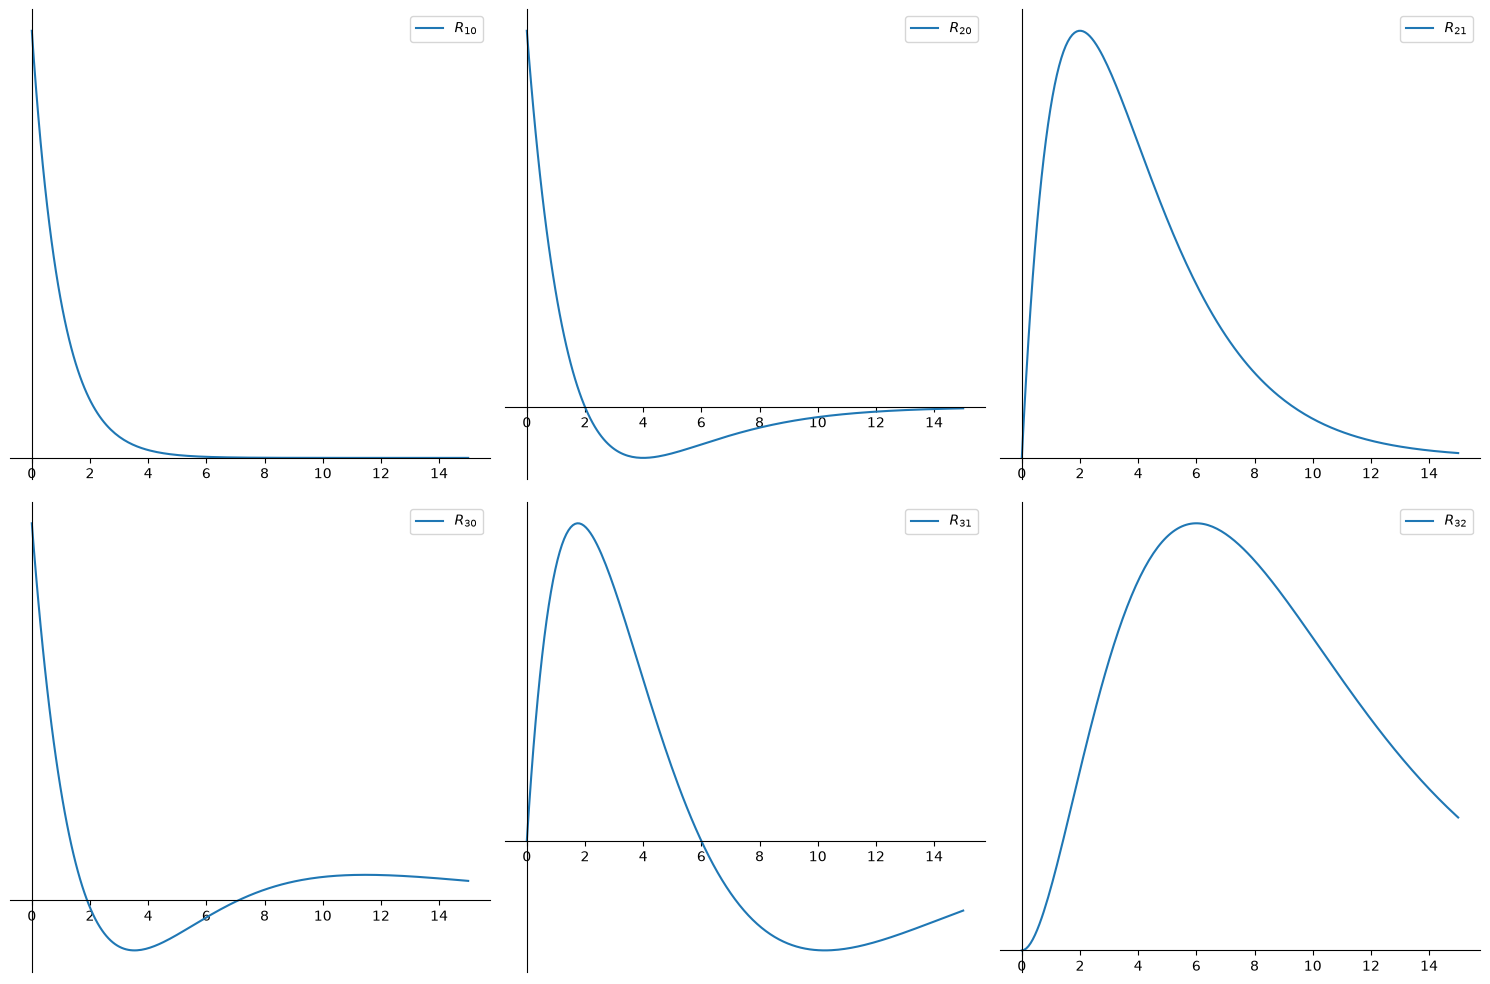

In [14]:
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()

for ax, (nn, ll) in zip(axes, orbitals_nl):
    R = funcs[(nn, ll)]
    ax.plot(r_vals, R(r_vals), label=f'$R_{{{nn}{ll}}}$')
    ax.set_yticks([])
    ax.spines['left'].set_position('zero')
    ax.spines['bottom'].set_position('zero')
    ax.spines['top'].set_color('none')
    ax.spines['right'].set_color('none')
    ax.xaxis.set_ticks_position('bottom')
    ax.yaxis.set_ticks_position('left')
    ax.legend()

plt.tight_layout()
plt.show()

### 7.2. Тривимірна форма $p$-орбіталей

Переходимо до декартових координат:

$$
x=|p(\theta,\phi)|\sin\theta\cos\phi,\quad y=|p(\theta,\phi)|\sin\theta\sin\phi,\quad z=|p(\theta,\phi)|\cos\theta
$$

Колір поверхні кодує знак хвильової функції в даному напрямку (червоний — додатний, синій — від'ємний). Форма — класична "гантель", витягнута вздовж відповідної осі.

In [15]:
from mpl_toolkits.mplot3d import Axes3D

theta_vals = np.linspace(0, np.pi, 50)
phi_vals = np.linspace(0, 2 * np.pi, 50)
Theta, Phi = np.meshgrid(theta_vals, phi_vals)

px_func = lambdify((theta, phi), px, 'numpy')
py_func = lambdify((theta, phi), py, 'numpy')
pz_func = lambdify((theta, phi), pz, 'numpy')

px_vals = px_func(Theta, Phi)
py_vals = py_func(Theta, Phi)
pz_vals = pz_func(Theta, Phi)

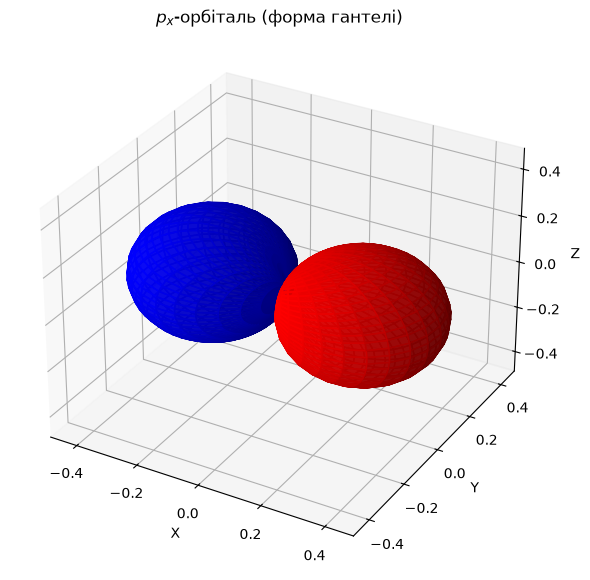

In [16]:
def to_cartesian(vals):
    X = np.abs(vals) * np.sin(Theta) * np.cos(Phi)
    Y = np.abs(vals) * np.sin(Theta) * np.sin(Phi)
    Zc = np.abs(vals) * np.cos(Theta)
    colors = np.where(vals >= 0, 'red', 'blue')
    return X, Y, Zc, colors

PxX, PxY, PxZ, colors_x = to_cartesian(px_vals)

fig = plt.figure(figsize=(8, 7))
ax = fig.add_subplot(111, projection='3d')
ax.plot_surface(PxX, PxY, PxZ, facecolors=colors_x, alpha=0.8)
ax.set_xlabel('X'); ax.set_ylabel('Y'); ax.set_zlabel('Z')
ax.set_title(r'$p_x$-орбіталь (форма гантелі)')

max_range = np.max([PxX.max(), PxY.max(), PxZ.max()])
ax.set_xlim([-max_range, max_range]); ax.set_ylim([-max_range, max_range]); ax.set_zlim([-max_range, max_range])
plt.show()

## 8. Спін електрона

Спін електрона — окремий, некласичний внутрішній ступінь свободи (не обертання!). Якби спін відповідав класичному обертанню, довелося б ввести ще два додаткові квантові числа, що дало б значно більше станів, ніж спостерігається експериментально.

За Паулі вводиться дискретна внутрішня змінна $\sigma$ з двома значеннями:

$$
\sigma=\uparrow\;(m_s=+\tfrac12), \qquad \sigma=\downarrow\;(m_s=-\tfrac12)
$$

Повна хвильова функція — двокомпонентний спінор:

$$
\Psi(\mathbf r,t)=\begin{pmatrix}\psi_\uparrow(\mathbf r,t)\\ \psi_\downarrow(\mathbf r,t)\end{pmatrix}
$$

або, без спін-орбітальної взаємодії, просто добуток просторової та спінової частин:

$$
\Psi_{\text{повна}} = \Psi_{nlm}(\mathbf r)\,\chi_{m_s}
$$

## 9. Висновки

1. Рівняння Шредінгера для атома водню розв'язується точно завдяки сферичній симетрії кулонівського потенціалу.
2. Кутова частина — сферичні гармоніки $Y_l^m$, власні функції $\hat{\mathbf L}^2$ та $\hat L_z$; визначають форму орбіталі.
3. Радіальна частина $R_{nl}(r)$, через поліноми Лагерра, визначає розподіл електрона за відстанню від ядра.
4. $E_n=-Z^2/(2n^2)$, кожен рівень вироджений $n^2$ разів.
5. Дійсні комбінації сферичних гармонік ($p_x,p_y,p_z$) мають напрямлені форми, зручні для хімії.
6. Спін — окремий внутрішній ступінь свободи, необхідний для узгодження з експериментом.
7. SymPy дозволяє відтворити й перевірити всі класичні результати теорії атома водню аналітично, без чисельних наближень.

## Контрольні питання

1. Чому для атома водню рівняння Шредінгера вдається розв'язати точно, а для гелію — ні?
2. Що фізично означає відцентровий доданок $l(l+1)/r^2$ в ефективному радіальному потенціалі?
3. Чому енергія $E_n$ не залежить від $l$ і $m$?
4. Скільки станів (без урахування спіну) має рівень з $n=3$? А з урахуванням спіну?
5. Покажіть, що $\langle T\rangle=-\tfrac12\langle U\rangle$ для основного стану (теорема віріала).
6. Чому $\langle r\rangle$ не збігається з борівським радіусом $a_0$?
7. Поясніть, чому спін не можна інтерпретувати як класичне обертання електрона.

## Завдання для самостійної практичної роботи

1. Повторіть обчислення розділу 6 для стану $n=2, l=0, m=0$ ($\psi_{200}$): перевірте нормування, знайдіть $\langle U\rangle$, $\langle T\rangle$, $\langle r\rangle$, порівняйте з $E_{n=2}=-Z^2/8$.
2. Побудуйте графік густини ймовірності $4\pi r^2|R_{nl}(r)|^2$ і знайдіть чисельно положення максимуму для $n=1,l=0$; порівняйте з $a_0/Z$.
3. За аналогією з розділом 6.8 побудуйте дійсні $d$-орбіталі ($l=2$) через `Ynm` і візуалізуйте їхню форму.
4. Перевірте ортогональність $Y_1^0$ і $Y_1^1$ прямим символьним інтегруванням по сфері.

## Джерела

1. Документація SymPy: [Hydrogen Wavefunctions](https://docs.sympy.org/latest/modules/physics/hydrogen.html)